In [1]:
%pip install shap

  Using cached shap-0.51.0-cp311-cp311-win_amd64.whl.metadata (26 kB)
Using cached shap-0.51.0-cp311-cp311-win_amd64.whl (554 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



DELAY: 0 of 13 features clearly above zero (mean > 2 std)
     feature   mean    std
 WarehouseID 0.0134 0.0101
n_categories 0.0030 0.0043
     max_qty 0.0000 0.0000

DEMAND: 0 of 8 features clearly above zero (mean > 2 std)
  feature   mean    std
UnitPrice 0.0191 0.0192
    lag_1 0.0000 0.0000
    lag_2 0.0000 0.0000

CUSTOMER: 2 of 15 features clearly above zero (mean > 2 std)
     feature    mean     std
 n_cancelled 87.3176 25.6128
n_orders_all 61.9606 28.0415
  share_Food 60.1629 43.9500

WAREHOUSE: 0 of 9 features clearly above zero (mean > 2 std)
           feature   mean    std
lag_avg_delay_days 0.0014 0.0033
    lag_delay_rate 0.0000 0.0000
   lag_n_shipments 0.0000 0.0000


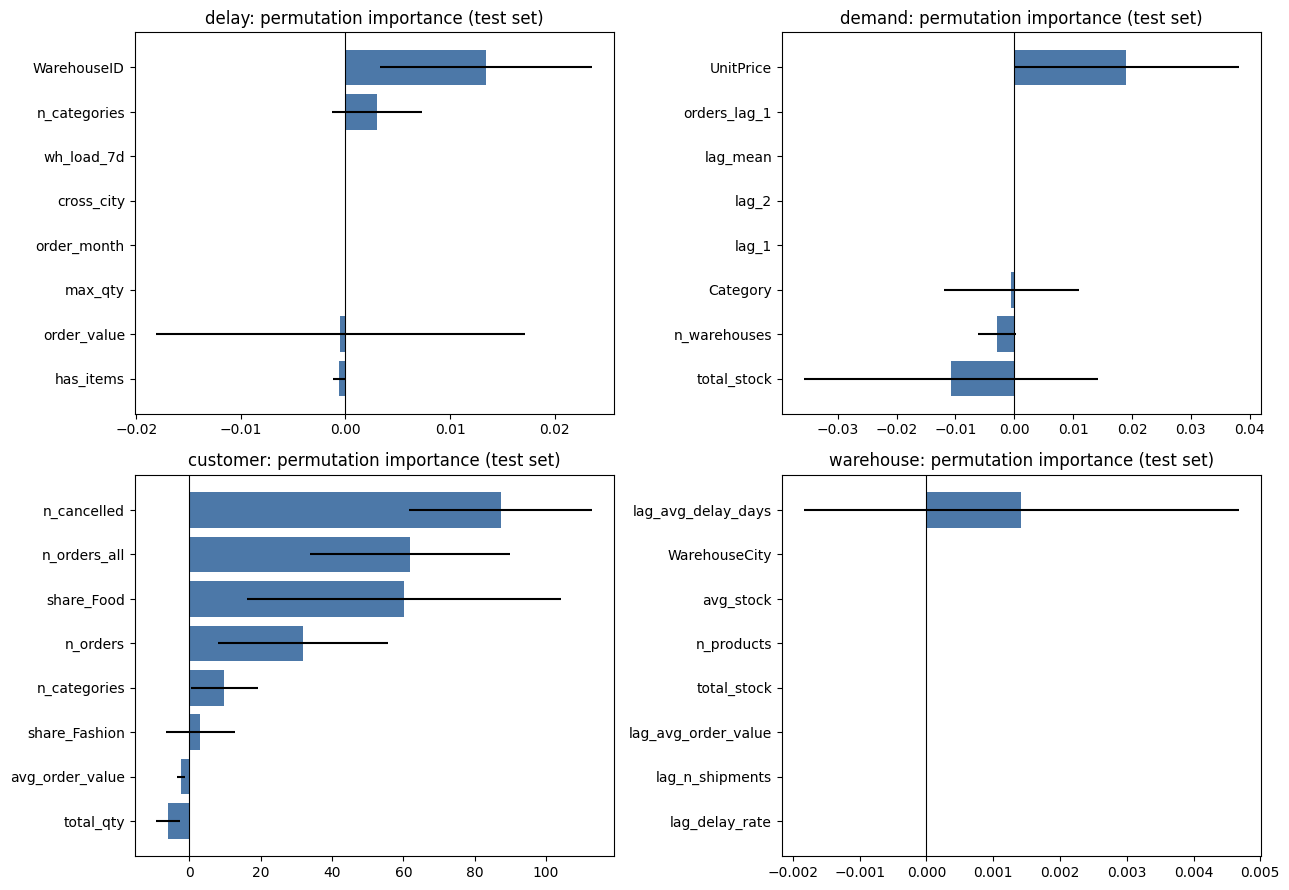

In [2]:
%load_ext autoreload
%autoreload 2

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.inspection import permutation_importance
from swiftlog_config import FEATURES
from swiftlog_utils import load_problem

MODELS = Path("../Models"); FIG = Path("../Reports/figures")
bundle = joblib.load(MODELS / "Best_Model.pkl")
SCORING = {"classification": "roc_auc", "regression": "neg_root_mean_squared_error"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
perm_tables = {}

for ax, name in zip(axes.ravel(), FEATURES):
    cfg, sets = load_problem(name)
    Xte, yte = sets["test"]
    pipe = bundle[name]["pipeline"]

    r = permutation_importance(pipe, Xte, yte, scoring=SCORING[cfg["task"]],
                               n_repeats=30, random_state=42, n_jobs=-1)
    t = pd.DataFrame({"feature": Xte.columns, "mean": r.importances_mean,
                      "std": r.importances_std}).sort_values("mean")
    perm_tables[name] = t.sort_values("mean", ascending=False).reset_index(drop=True)

    top = t.tail(8)
    ax.barh(top["feature"], top["mean"], xerr=top["std"], color="#4C78A8")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{name}: permutation importance (test set)")

    n_clear = int((t["mean"] > 2 * t["std"]).sum())
    print(f"\n{name.upper()}: {n_clear} of {len(t)} features clearly above zero (mean > 2 std)")
    print(perm_tables[name].head(3).round(4).to_string(index=False))

plt.tight_layout()
plt.savefig(MODELS / "Feature_Importance.png", dpi=150)
plt.savefig(FIG / "permutation_importance.png", dpi=150)
plt.show()

c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


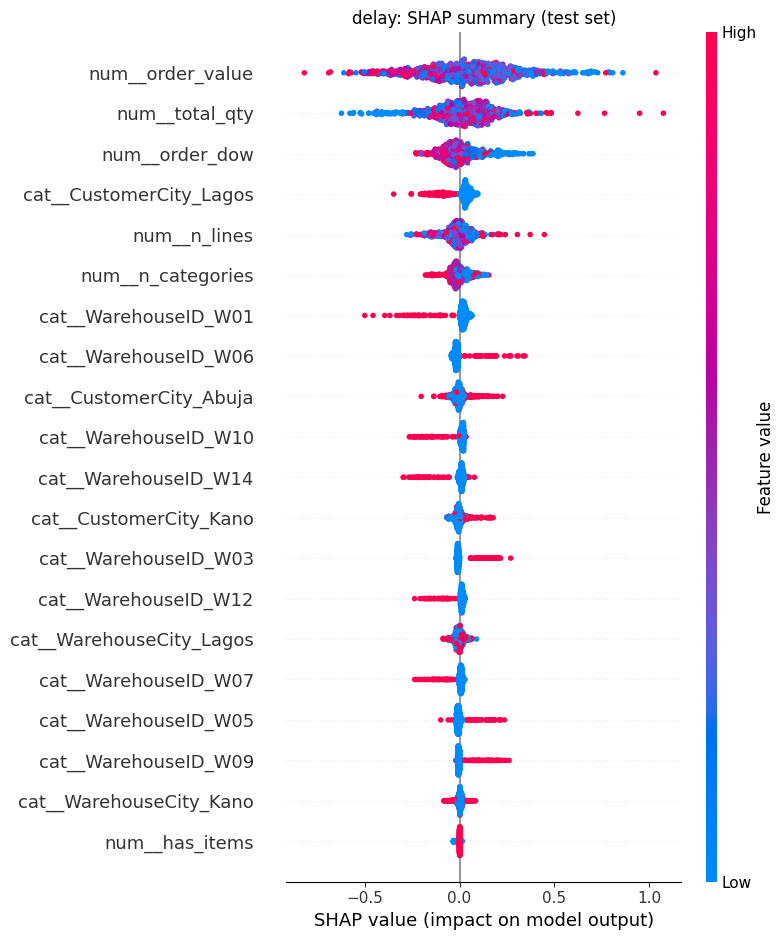

DELAY mean |SHAP| top 3: {'num__order_value': 0.1989, 'num__total_qty': 0.1277, 'num__order_dow': 0.0744}


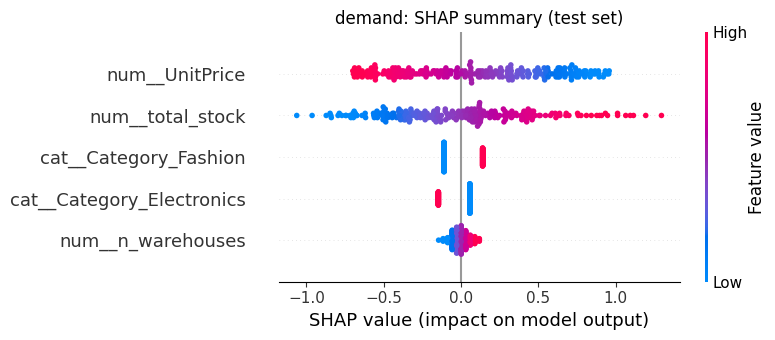

DEMAND mean |SHAP| top 3: {'num__UnitPrice': 0.4192, 'num__total_stock': 0.3665, 'cat__Category_Fashion': 0.1215}


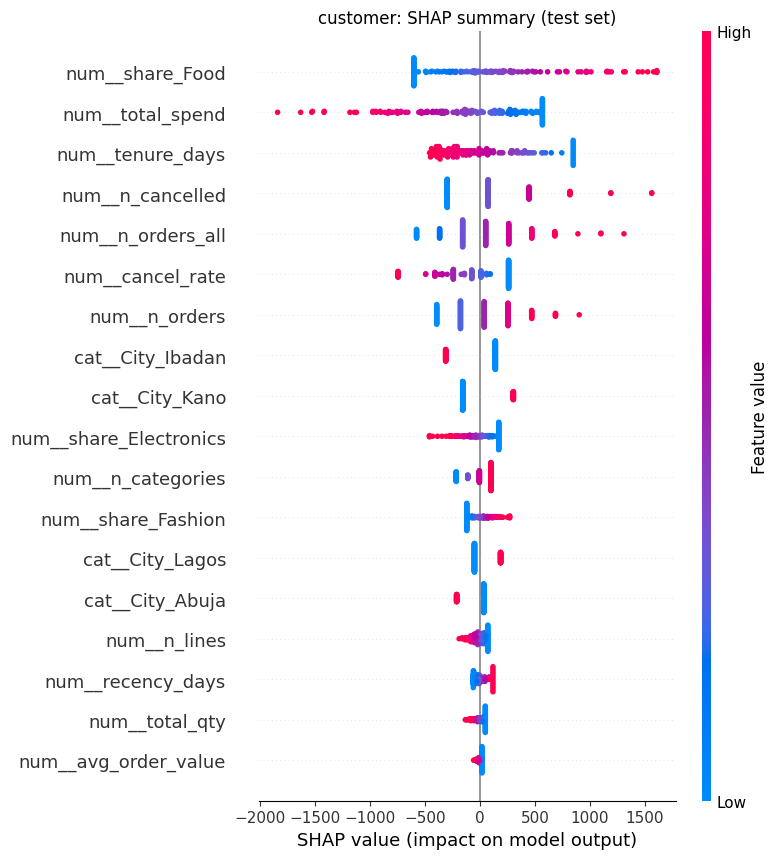

CUSTOMER mean |SHAP| top 3: {'num__share_Food': 504.1418, 'num__total_spend': 463.2889, 'num__tenure_days': 318.4352}


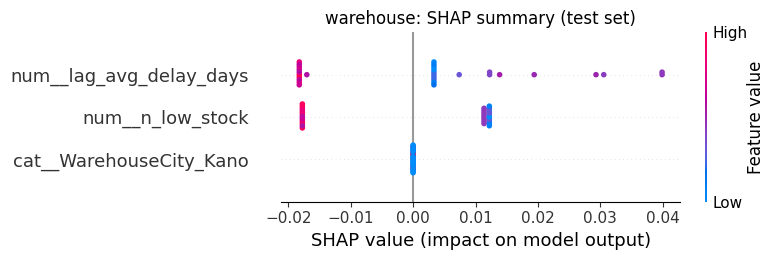

WAREHOUSE mean |SHAP| top 3: {'num__lag_avg_delay_days': 0.0146, 'num__n_low_stock': 0.0142, 'cat__WarehouseCity_Kano': 0.0}


In [3]:
import shap
from scipy import sparse

def shap_inputs(pipe, X):
    prep, sel = pipe.named_steps["prep"], pipe.named_steps["select"]
    Xt = sel.transform(prep.transform(X))
    if sparse.issparse(Xt):
        Xt = Xt.toarray()
    names = prep.get_feature_names_out()[sel.get_support()]
    return Xt, names

for name in FEATURES:
    cfg, sets = load_problem(name)
    Xtr, _ = sets["train"]; Xte, _ = sets["test"]
    pipe = bundle[name]["pipeline"]
    model = pipe.named_steps["model"]

    Xtr_t, names = shap_inputs(pipe, Xtr)
    Xte_t, _ = shap_inputs(pipe, Xte)
    bg = shap.sample(Xtr_t, 100, random_state=42)

    sv = shap.Explainer(model, bg)(Xte_t)
    vals = sv.values if sv.values.ndim == 2 else sv.values[:, :, 1]

    shap.summary_plot(vals, Xte_t, feature_names=names, show=False)
    plt.title(f"{name}: SHAP summary (test set)")
    plt.tight_layout()
    plt.savefig(FIG / f"shap_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

    top = pd.Series(np.abs(vals).mean(axis=0), index=names).sort_values(ascending=False).head(3)
    print(name.upper(), "mean |SHAP| top 3:", top.round(4).to_dict())

In [4]:
from sklearn.metrics import roc_auc_score, r2_score

cfg, sets = load_problem("delay"); Xte, yte = sets["test"]
pipe, thr = bundle["delay"]["pipeline"], bundle["delay"]["threshold"]
pred = (pipe.predict_proba(Xte)[:, 1] >= thr).astype(int)
err = Xte.assign(y=yte.values, pred=pred)
err["correct"] = err["y"] == err["pred"]
print("DELAY accuracy by warehouse (test):")
print(err.groupby("WarehouseID")["correct"].mean().round(2).to_string())
ot = err[err["y"] == 0]
print(f"On Time shipments correctly identified: {int((ot['pred'] == 0).sum())} of {len(ot)}\n")

for name, col in [("demand", "Category"), ("customer", "City"), ("warehouse", "WarehouseCity")]:
    cfg, sets = load_problem(name); Xte, yte = sets["test"]
    p = bundle[name]["pipeline"].predict(Xte)
    r = pd.DataFrame({"group": Xte[col].values, "abs_err": np.abs(yte.values - p),
                      "bias": yte.values - p})
    print(f"{name.upper()} error by {col}:")
    print(r.groupby("group").agg(MAE=("abs_err", "mean"), bias=("bias", "mean"),
                                 n=("group", "size")).round(2).to_string(), "\n")

cfg, sets = load_problem("customer"); Xte, yte = sets["test"]
p = bundle["customer"]["pipeline"].predict(Xte); z = yte.values == 0
print(f"CUSTOMER MAE for zero-spenders: {np.abs(p[z]).mean():.0f} | for spenders: {np.abs(yte.values[~z] - p[~z]).mean():.0f}\n")

rng = np.random.RandomState(42)
for name in FEATURES:
    cfg, sets = load_problem(name); Xte, yte = sets["test"]
    pipe = bundle[name]["pipeline"]
    if cfg["task"] == "classification":
        s, f = pipe.predict_proba(Xte)[:, 1], roc_auc_score
    else:
        s, f = pipe.predict(Xte), r2_score
    real = f(yte, s)
    null = np.array([f(rng.permutation(yte.values), s) for _ in range(1000)])
    print(f"{name:10s} real={real:.3f}  random-label mean={null.mean():.3f}  p-value={(null >= real).mean():.3f}")

DELAY accuracy by warehouse (test):
WarehouseID
W01    0.66
W02    0.62
W03    0.62
W04    0.72
W05    0.82
W06    0.62
W07    0.57
W08    0.65
W09    0.68
W10    0.56
W11    0.74
W12    0.76
W13    0.61
W14    0.60
W15    0.64
On Time shipments correctly identified: 1 of 259

DEMAND error by Category:
               MAE  bias   n
group                       
Electronics  11.85  2.56  78
Fashion      10.73  2.41  95
Food         11.59  6.19  77 

CUSTOMER error by City:
            MAE     bias   n
group                       
Abuja   4303.33   720.20  32
Ibadan  5151.30  1302.77  45
Kano    4779.19 -1393.32  34
Lagos   4351.61  -104.28  42 

WAREHOUSE error by WarehouseCity:
        MAE  bias   n
group                
Abuja  0.06  0.01   8
Kano   0.08  0.00   6
Lagos  0.06  0.01  16 

CUSTOMER MAE for zero-spenders: 5299 | for spenders: 4434

delay      real=0.492  random-label mean=0.500  p-value=0.642
demand     real=-0.064  random-label mean=-0.066  p-value=0.358
customer   real=-0

In [5]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
